# 27. Text Classification

## Overview
Text classification assigns predefined labels to documents, such as positive/negative sentiment, topic categories, or spam/ham. A typical machine learning pipeline transforms raw text into numerical features and trains a classifier on labeled examples.

This notebook builds an end-to-end baseline using TF-IDF and Logistic Regression.

## 1. Import libraries

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 2. Prepare labeled text data

The small dataset is illustrative. For real applications, use a larger dataset with representative examples and carefully checked labels.

In [2]:
data = [
    ("The product is excellent and works perfectly", "positive"),
    ("I love the quality and the fast delivery", "positive"),
    ("Very useful and easy to operate", "positive"),
    ("The support team was helpful and kind", "positive"),
    ("This is a fantastic purchase", "positive"),
    ("The experience was wonderful", "positive"),
    ("The product broke after one day", "negative"),
    ("Very poor quality and disappointing results", "negative"),
    ("I am unhappy with this purchase", "negative"),
    ("The service was slow and unhelpful", "negative"),
    ("It stopped working and cannot be repaired", "negative"),
    ("A frustrating and terrible experience", "negative"),
    ("The book explains algorithms clearly", "neutral"),
    ("The package contains three items", "neutral"),
    ("The meeting is scheduled for Monday", "neutral"),
    ("This model has twelve input features", "neutral"),
    ("The report includes a table of results", "neutral"),
    ("The device comes in two sizes", "neutral"),
]

df = pd.DataFrame(data, columns=["text", "label"])
display(df.head())
print(df["label"].value_counts())

,text,label
0,The product is excellent and works perfectly,positive
1,I love the quality and the fast delivery,positive
2,Very useful and easy to operate,positive
3,The support team was helpful and kind,positive
4,This is a fantastic purchase,positive


label
positive    6
negative    6
neutral     6
Name: count, dtype: int64


## 3. Split the dataset

Stratification preserves the approximate class distribution in both sets. The test set should remain untouched during model selection.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.33,
    random_state=42,
    stratify=df["label"],
)

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))

Training examples: 12
Test examples: 6


## 4. Build a machine learning pipeline

The pipeline fits TF-IDF on training text and passes the resulting features to Logistic Regression. Using a pipeline helps prevent preprocessing leakage.

In [4]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), lowercase=True)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

model.fit(X_train, y_train)
print("Training complete.")

Training complete.


## 5. Evaluate predictions

Accuracy is the fraction of test examples classified correctly. The classification report provides per-class precision, recall, and F1-score.

In [5]:
y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.167
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
     neutral       0.00      0.00      0.00         2
    positive       0.25      0.50      0.33         2

    accuracy                           0.17         6
   macro avg       0.08      0.17      0.11         6
weighted avg       0.08      0.17      0.11         6



## 6. Visualize the confusion matrix

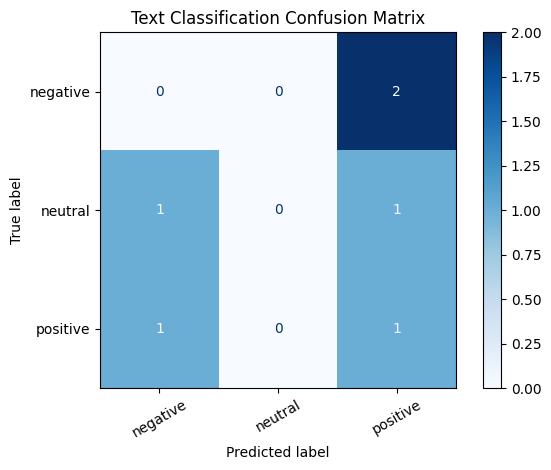

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"],
    xticks_rotation=30,
    cmap="Blues",
)
plt.title("Text Classification Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Predict labels for new text

The same fitted pipeline can classify new documents without manually transforming them.

In [7]:
new_texts = [
    "The service was excellent and the staff were helpful",
    "The product stopped working and the quality is poor",
    "The package includes a cable and a user guide",
]

predictions = model.predict(new_texts)

for text, label in zip(new_texts, predictions):
    print(f"Text: {text}\nPredicted label: {label}\n")

Text: The service was excellent and the staff were helpful
Predicted label: positive

Text: The product stopped working and the quality is poor
Predicted label: positive

Text: The package includes a cable and a user guide
Predicted label: neutral



## Interpretation and limitations

- This dataset is intentionally small and synthetic, so its test score is not a reliable estimate of real-world performance.
- A random split can be unstable with very few examples.
- Real projects should use more data, compare baselines, and tune models using cross-validation.
- Label definitions, class imbalance, and domain shift can materially affect performance.

## Summary

This notebook demonstrates the core text-classification workflow: labeled data, train/test split, TF-IDF features, a classifier, evaluation, and predictions on new examples.